## Imports

In [1]:
#Imports 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,  LabelEncoder

# Models 
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Pipeline
from sklearn.pipeline import Pipeline

# Evaluation methods 
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.metrics import mean_squared_error, r2_score

# Hyperparameter tuning 
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit



## 1. Data Loading & Cleaning
Loads six Premier League seasons from football-data-co.uk, merges per-match xG data from the Kaggle dataset "EPL Expected Goals stats (2014-2025)", standardizes team names, and keeps only matches with xG (xG source ends on 2025-12-02)

In [2]:
# Combining all historical match data

epl_20_21 = pd.read_csv("data/epl-20-21.csv")
epl_21_22 = pd.read_csv("data/epl-21-22.csv")
epl_22_23 = pd.read_csv("data/epl-22-23.csv")
epl_23_24 = pd.read_csv("data/epl-23-24.csv")
epl_24_25 = pd.read_csv("data/epl-24-25.csv")
epl_25_26 = pd.read_csv("data/epl-25-26.csv")

matches = pd.concat(
    [epl_20_21, epl_21_22, epl_22_23, epl_23_24, epl_24_25, epl_25_26],
    ignore_index = True
)

# Combining xG dataset 
xg_data = pd.read_csv("data/epl-xg-data.csv")
# Removing duplicated rows from csv
xg_data = xg_data.drop_duplicates(subset=['Date', 'HomeTeam', 'AwayTeam'])

# xG data has different names
team_name = {
    'Man City': 'Manchester City',
    'Man United': 'Manchester United',
    'Newcastle': 'Newcastle United',
    "Nott'm Forest": 'Nottingham Forest',
    'West Brom': 'West Bromwich Albion',
    'Wolves': 'Wolverhampton Wanderers',
}

matches['HomeTeam'] = matches['HomeTeam'].replace(team_name)
matches['AwayTeam'] = matches['AwayTeam'].replace(team_name)

# Convert dates
matches['Date'] = pd.to_datetime(matches['Date'], format='%d/%m/%Y')
xg_data['Date'] = pd.to_datetime(xg_data['Date'], format='%d/%m/%Y')

# Match and merge xG data to dataframe
matches = matches.merge(
    xg_data[['Date', 'HomeTeam', 'AwayTeam', 'xg_home', 'xg_away']],
    on=['Date', 'HomeTeam', 'AwayTeam'],
    how='left'   
)



In [3]:
# Cleaning 

columns_to_keep = [
    'Date', 'HomeTeam', 'AwayTeam',
    'FTHG', 'FTAG', 'FTR',
    'HS', 'AS', 'HST', 'AST',
    'HC', 'AC',
    'HY', 'AY', 'HR', 'AR',
    'B365H', 'B365D', 'B365A',
    'xg_home', 'xg_away'
]

matches = matches[columns_to_keep]
# xG data only goes upto December 2 2025 remove rows after cutoff
matches = matches.dropna(subset=['xg_home', 'xg_away']).reset_index(drop = True)
# Order chronologically 
matches = matches.sort_values('Date').reset_index(drop=True)

matches.shape

(2033, 21)

## 2. Feature Engineering
Every feature uses information available only before kick-off. Each team's recent form is an average over its previous 5 matches (shifted by one game so the current match is excluded), plus head-to-head record and a newly-promoted flag. Features are built per team first, then merged back so each match has their home and away features side by side 

In [4]:
# Transform full-time result into numerical values (A:0 D:1 H:2)
le = LabelEncoder()
matches['FTR_encoded'] = le.fit_transform(matches['FTR'])

# Split match data into home and away for consistency
home_df = matches[['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'xg_home', 'xg_away',
                    'HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR']].copy()
# Rename features
home_df.columns = ['Date', 'Team', 'Opponent', 'GoalsFor', 'GoalsAgainst', 'FTR', 'xGFor', 'xGAgainst',
                    'ShotsFor', 'ShotsAgainst', 'ShotsOnTargetFor', 'ShotsOnTargetAgainst',
                    'CornersFor', 'CornersAgainst', 'YellowsFor', 'YellowsAgainst', 'RedsFor', 'RedsAgainst']
# Add points column (win 3 points, draw 1 point, loss 0 points)
home_df['Points'] = home_df['FTR'].map({'H': 3, 'D': 1, 'A': 0})
home_df['Venue'] = 'Home'

# Repeat for away
away_df = matches[['Date', 'AwayTeam', 'HomeTeam' , 'FTAG', 'FTHG', 'FTR', 'xg_away', 'xg_home',
                    'AS', 'HS', 'AST', 'HST', 'AC', 'HC', 'AY', 'HY', 'AR', 'HR']].copy()
away_df.columns = ['Date', 'Team', 'Opponent', 'GoalsFor', 'GoalsAgainst', 'FTR', 'xGFor', 'xGAgainst',
                    'ShotsFor', 'ShotsAgainst', 'ShotsOnTargetFor', 'ShotsOnTargetAgainst',
                    'CornersFor', 'CornersAgainst', 'YellowsFor', 'YellowsAgainst', 'RedsFor', 'RedsAgainst']
away_df['Points'] = away_df['FTR'].map({'A': 3, 'D': 1, 'H': 0})
away_df['Venue'] = 'Away'

#Combine and sort by team
team_matches = pd.concat([home_df, away_df], ignore_index=True)
team_matches = team_matches.sort_values(['Team', 'Date']).reset_index(drop=True)

# Replace FTR with team perspective result
team_matches['Result'] = team_matches['Points'].map({3: 'W', 1: 'D', 0: 'L'})
team_matches = team_matches.drop(columns=['FTR'])

# Reorder columns
column_order = ['Date', 'Team', 'Venue', 'Opponent', 'Result', 'Points', 'GoalsFor', 'GoalsAgainst',  'xGFor', 'xGAgainst',
                 'ShotsFor', 'ShotsAgainst', 'ShotsOnTargetFor', 'ShotsOnTargetAgainst',
                 'CornersFor', 'CornersAgainst', 'YellowsFor', 'YellowsAgainst', 'RedsFor', 'RedsAgainst']
team_matches = team_matches[column_order]

In [5]:
# Adding form feature for teams last 5 results
team_matches['Form_Points'] = (
    team_matches.groupby('Team')['Points'].transform(lambda x: x.shift(1).rolling(5).sum())
)

# Adding average goals scored and conceded for teams last 5 results
team_matches['Form_GoalsFor'] = (
    team_matches.groupby('Team')['GoalsFor'].transform(lambda x: x.shift(1).rolling(5).mean())
)
team_matches['Form_GoalsAgainst'] = (
    team_matches.groupby('Team')['GoalsAgainst'].transform(lambda x: x.shift(1).rolling(5).mean())
)

# Adding average xG for and conceded for teams last 5 results
team_matches['Form_xGFor'] = (
    team_matches.groupby('Team')['xGFor'].transform(lambda x: x.shift(1).rolling(5).mean())
)
team_matches['Form_xGAgainst'] = (
    team_matches.groupby('Team')['xGAgainst'].transform(lambda x: x.shift(1).rolling(5).mean())
)

# Adding rolling averages for shots, shots on target, corners, and cards
new_stats = ['ShotsFor', 'ShotsAgainst', 'ShotsOnTargetFor', 'ShotsOnTargetAgainst',
             'CornersFor', 'CornersAgainst', 'YellowsFor', 'YellowsAgainst', 'RedsFor', 'RedsAgainst']

for stat in new_stats:
    team_matches[f'Form_{stat}'] = (
        team_matches.groupby('Team')[stat].transform(lambda x: x.shift(1).rolling(5).mean())
    )

# Adding a H2H feature to calculate average points earned against certain teams
def calculate_h2h_points(group):
    return group['Points'].shift(1).expanding().mean()
team_matches['H2H_Avg_Points'] = (
    team_matches.groupby(['Team','Opponent']).apply(calculate_h2h_points).reset_index(level=[0,1], drop=True)
)

# Adding a feature to determine whether a team has been newly promoted

# Get the list of teams present in each season
matches['Season'] = matches['Date'].apply(lambda d: d.year if d.month >= 8 else d.year - 1)
teams_by_season = matches.groupby('Season')['HomeTeam'].unique()


seasons_sorted = sorted(teams_by_season.index)

promoted_teams_by_season = {}
for i in range(1, len(seasons_sorted)):
    current_season = seasons_sorted[i]
    previous_season = seasons_sorted[i-1]

    current_teams = set(teams_by_season[current_season])
    previous_teams = set(teams_by_season[previous_season])

    newly_promoted = current_teams - previous_teams
    promoted_teams_by_season[current_season] = newly_promoted

# Add season column to data frame
team_matches['Season'] = team_matches['Date'].apply(lambda d: d.year if d.month >= 8 else d.year - 1)

def is_promoted(row):
    season = row['Season']
    team = row['Team']
    if season not in promoted_teams_by_season:
        return 0
    return 1 if team in promoted_teams_by_season[season] else 0

team_matches['IsNewlyPromoted'] = team_matches.apply(is_promoted, axis=1)

# Merge added features

feature_columns = ['Date', 'Team', 'Opponent', 'Form_Points', 'Form_GoalsFor', 'Form_GoalsAgainst', 'Form_xGFor', 'Form_xGAgainst',
                    'Form_ShotsFor', 'Form_ShotsAgainst', 'Form_ShotsOnTargetFor', 'Form_ShotsOnTargetAgainst',
                    'Form_CornersFor', 'Form_CornersAgainst', 'Form_YellowsFor', 'Form_YellowsAgainst', 'Form_RedsFor', 'Form_RedsAgainst',
                    'H2H_Avg_Points', 'IsNewlyPromoted']
features_only = team_matches[feature_columns]

# Merge Home team features
matches = matches.merge(
    features_only,
    left_on=['Date', 'HomeTeam', 'AwayTeam'],
    right_on=['Date', 'Team', 'Opponent'],
    how='left'
)

# rename features for home team
matches = matches.rename(columns={
    'Form_Points': 'Home_Form_Points',
    'Form_GoalsFor': 'Home_Form_GoalsFor',
    'Form_GoalsAgainst': 'Home_Form_GoalsAgainst',
    'Form_xGFor': 'Home_Form_xGFor',
    'Form_xGAgainst': 'Home_Form_xGAgainst',
    'Form_ShotsFor': 'Home_Form_ShotsFor',
    'Form_ShotsAgainst': 'Home_Form_ShotsAgainst',
    'Form_ShotsOnTargetFor': 'Home_Form_ShotsOnTargetFor',
    'Form_ShotsOnTargetAgainst': 'Home_Form_ShotsOnTargetAgainst',
    'Form_CornersFor': 'Home_Form_CornersFor',
    'Form_CornersAgainst': 'Home_Form_CornersAgainst',
    'Form_YellowsFor': 'Home_Form_YellowsFor',
    'Form_YellowsAgainst': 'Home_Form_YellowsAgainst',
    'Form_RedsFor': 'Home_Form_RedsFor',
    'Form_RedsAgainst': 'Home_Form_RedsAgainst',
    'H2H_Avg_Points': 'Home_H2H_Avg_Points',
    'IsNewlyPromoted': 'Home_IsNewlyPromoted'
})
matches = matches.drop(columns=['Team', 'Opponent'])

# Merge away team features
matches = matches.merge(
    features_only,
    left_on=['Date', 'AwayTeam', 'HomeTeam'],
    right_on=['Date', 'Team', 'Opponent'],
    how='left'
)
#rename features for away team
matches = matches.rename(columns={
    'Form_Points': 'Away_Form_Points',
    'Form_GoalsFor': 'Away_Form_GoalsFor',
    'Form_GoalsAgainst': 'Away_Form_GoalsAgainst',
    'Form_xGFor': 'Away_Form_xGFor',
    'Form_xGAgainst': 'Away_Form_xGAgainst',
    'Form_ShotsFor': 'Away_Form_ShotsFor',
    'Form_ShotsAgainst': 'Away_Form_ShotsAgainst',
    'Form_ShotsOnTargetFor': 'Away_Form_ShotsOnTargetFor',
    'Form_ShotsOnTargetAgainst': 'Away_Form_ShotsOnTargetAgainst',
    'Form_CornersFor': 'Away_Form_CornersFor',
    'Form_CornersAgainst': 'Away_Form_CornersAgainst',
    'Form_YellowsFor': 'Away_Form_YellowsFor',
    'Form_YellowsAgainst': 'Away_Form_YellowsAgainst',
    'Form_RedsFor': 'Away_Form_RedsFor',
    'Form_RedsAgainst': 'Away_Form_RedsAgainst',
    'H2H_Avg_Points': 'Away_H2H_Avg_Points',
    'IsNewlyPromoted': 'Away_IsNewlyPromoted'
})
matches = matches.drop(columns=['Team', 'Opponent'])

# Removing missing values
#check what is missing
matches.isna().sum()

# For missing values in H2H column impute missing values with a neatral value
h2h_cols = ['Home_H2H_Avg_Points', 'Away_H2H_Avg_Points']
matches[h2h_cols] = matches[h2h_cols].fillna(1.0)

# Drop rows with missing data
form_cols = [
    'Home_Form_Points', 'Home_Form_GoalsFor', 'Home_Form_GoalsAgainst', 'Home_Form_xGFor', 'Home_Form_xGAgainst',
    'Home_Form_ShotsFor', 'Home_Form_ShotsAgainst', 'Home_Form_ShotsOnTargetFor', 'Home_Form_ShotsOnTargetAgainst',
    'Home_Form_CornersFor', 'Home_Form_CornersAgainst', 'Home_Form_YellowsFor', 'Home_Form_YellowsAgainst',
    'Home_Form_RedsFor', 'Home_Form_RedsAgainst',
    'Away_Form_Points', 'Away_Form_GoalsFor', 'Away_Form_GoalsAgainst', 'Away_Form_xGFor', 'Away_Form_xGAgainst',
    'Away_Form_ShotsFor', 'Away_Form_ShotsAgainst', 'Away_Form_ShotsOnTargetFor', 'Away_Form_ShotsOnTargetAgainst',
    'Away_Form_CornersFor', 'Away_Form_CornersAgainst', 'Away_Form_YellowsFor', 'Away_Form_YellowsAgainst',
    'Away_Form_RedsFor', 'Away_Form_RedsAgainst'
]
matches = matches.dropna(subset=form_cols).reset_index(drop=True)

print(matches.shape)
matches.isna().sum()

(1942, 57)


Date                              0
HomeTeam                          0
AwayTeam                          0
FTHG                              0
FTAG                              0
FTR                               0
HS                                0
AS                                0
HST                               0
AST                               0
HC                                0
AC                                0
HY                                0
AY                                0
HR                                0
AR                                0
B365H                             0
B365D                             0
B365A                             0
xg_home                           0
xg_away                           0
FTR_encoded                       0
Season                            0
Home_Form_Points                  0
Home_Form_GoalsFor                0
Home_Form_GoalsAgainst            0
Home_Form_xGFor                   0
Home_Form_xGAgainst         

In [6]:
column_order = [
    'Date', 'Season',
    'HomeTeam', 'AwayTeam',
    'FTR', 'FTR_encoded',
    'FTHG', 'FTAG',
    'xg_home', 'xg_away',
    'HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HY', 'AY', 'HR', 'AR',
    'Home_Form_Points', 'Home_Form_GoalsFor', 'Home_Form_GoalsAgainst', 'Home_Form_xGFor', 'Home_Form_xGAgainst',
    'Home_Form_ShotsFor', 'Home_Form_ShotsAgainst', 'Home_Form_ShotsOnTargetFor', 'Home_Form_ShotsOnTargetAgainst',
    'Home_Form_CornersFor', 'Home_Form_CornersAgainst', 'Home_Form_YellowsFor', 'Home_Form_YellowsAgainst',
    'Home_Form_RedsFor', 'Home_Form_RedsAgainst',
    'Home_H2H_Avg_Points', 'Home_IsNewlyPromoted',
    'Away_Form_Points', 'Away_Form_GoalsFor', 'Away_Form_GoalsAgainst', 'Away_Form_xGFor', 'Away_Form_xGAgainst',
    'Away_Form_ShotsFor', 'Away_Form_ShotsAgainst', 'Away_Form_ShotsOnTargetFor', 'Away_Form_ShotsOnTargetAgainst',
    'Away_Form_CornersFor', 'Away_Form_CornersAgainst', 'Away_Form_YellowsFor', 'Away_Form_YellowsAgainst',
    'Away_Form_RedsFor', 'Away_Form_RedsAgainst',
    'Away_H2H_Avg_Points', 'Away_IsNewlyPromoted',
    'B365H', 'B365D', 'B365A'
]

matches = matches[column_order]
print(matches.shape)
matches.head()

(1942, 57)


,Date,Season,HomeTeam,AwayTeam,FTR,FTR_encoded,FTHG,FTAG,xg_home,xg_away,...,Away_Form_CornersAgainst,Away_Form_YellowsFor,Away_Form_YellowsAgainst,Away_Form_RedsFor,Away_Form_RedsAgainst,Away_H2H_Avg_Points,Away_IsNewlyPromoted,B365H,B365D,B365A
0,2020-10-24,2020,Fulham,Crystal Palace,A,0,1,2,1.052580,2.810490,...,6.2,1.8,1.6,0.0,0.2,1.0,0,2.75,3.10,2.70
1,2020-10-24,2020,Liverpool,Sheffield United,H,2,2,1,2.402860,1.397880,...,5.8,1.2,1.4,0.2,0.0,1.0,0,1.22,6.50,12.00
2,2020-10-25,2020,Southampton,Everton,H,2,2,0,0.741510,0.287054,...,5.6,1.0,1.4,0.2,0.2,1.0,0,2.75,3.40,2.55
3,2020-10-25,2020,Wolverhampton Wanderers,Newcastle United,D,1,1,1,0.758626,0.253685,...,6.0,2.4,1.4,0.0,0.2,1.0,0,1.75,3.50,5.25
4,2020-10-25,2020,Arsenal,Leicester,A,0,0,1,0.739440,0.736172,...,4.0,2.2,1.8,0.0,0.0,1.0,0,1.90,3.75,3.80


## 3. Train/Test Split
Data was split chronologically, 2020-21 to 2023-24 for training and 2024-25 for testing. The 128 matches from 2025-26 are not used. The model uses 18 features: form(points, goals for, and goals against), xG, and shots on target for both teams, head-to-head, and a promotion flag. Total shots, corners, and cards were also engineered but left out because they did not consistently improve time-ordered cross-validation on the training data.


In [7]:
# 25/26 season left out due to missing data
train = matches[matches['Season'].isin([2020, 2021, 2022, 2023])].reset_index(drop=True)
test = matches[matches['Season'] == 2024].reset_index(drop=True)

In [8]:
# 18 features in total, all known before kick-off
features = [
    'Home_Form_Points', 'Home_Form_GoalsFor', 'Home_Form_GoalsAgainst',
    'Home_Form_xGFor', 'Home_Form_xGAgainst',
    'Home_Form_ShotsOnTargetFor', 'Home_Form_ShotsOnTargetAgainst',
    'Home_H2H_Avg_Points', 'Home_IsNewlyPromoted',
    'Away_Form_Points', 'Away_Form_GoalsFor', 'Away_Form_GoalsAgainst',
    'Away_Form_xGFor', 'Away_Form_xGAgainst',
    'Away_Form_ShotsOnTargetFor', 'Away_Form_ShotsOnTargetAgainst',
    'Away_H2H_Avg_Points', 'Away_IsNewlyPromoted'
]

# target is the numerical values for the full-time result
target = 'FTR_encoded'
X_train = train[features]
X_test = test[features]

y_train = train[target]
y_test = test[target]

print(train.shape, test.shape, X_train.shape)

(1439, 57) (375, 57) (1439, 18)


## 4. Classification: Baseline Model
Logistic regression on scaled features, in a default version and a class-balanced version (balanced gives more weight to draws, as the outcome is rare).


In [9]:
# Fit scaler on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
# Default
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

# Balanced
log_reg_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
log_reg_balanced.fit(X_train_scaled, y_train)
y_pred_lr_balanced = log_reg_balanced.predict(X_test_scaled)

## 5. Classification: Evaluation
Compared against a naive baseline (always predicting a home win), using accuracy, confusion matrix, precision, and recall.


In [11]:
# Naive baseline (always predict home win)
print(y_test.value_counts(normalize=True))

FTR_encoded
2    0.410667
0    0.349333
1    0.240000
Name: proportion, dtype: float64


In [12]:
print("DEFAULT ")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))

print("BALANCED ")
print("Accuracy:", accuracy_score(y_test, y_pred_lr_balanced))
print(confusion_matrix(y_test, y_pred_lr_balanced))
print(classification_report(y_test, y_pred_lr_balanced, target_names=le.classes_))

DEFAULT 
Accuracy: 0.544
[[ 74   1  56]
 [ 33   0  57]
 [ 24   0 130]]
              precision    recall  f1-score   support

           A       0.56      0.56      0.56       131
           D       0.00      0.00      0.00        90
           H       0.53      0.84      0.65       154

    accuracy                           0.54       375
   macro avg       0.37      0.47      0.41       375
weighted avg       0.42      0.54      0.47       375

BALANCED 
Accuracy: 0.5066666666666667
[[ 69  27  35]
 [ 34  16  40]
 [ 25  24 105]]
              precision    recall  f1-score   support

           A       0.54      0.53      0.53       131
           D       0.24      0.18      0.20        90
           H       0.58      0.68      0.63       154

    accuracy                           0.51       375
   macro avg       0.45      0.46      0.46       375
weighted avg       0.49      0.51      0.49       375



## 6. Classification: Model Comparison
Random forest (default and balanced) compared against logistic regression.


In [13]:
# Default
rf = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("RANDOM FOREST: DEFAULT ")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

# Balanced
rf_balanced = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10,
                                     class_weight='balanced', random_state=42)
rf_balanced.fit(X_train, y_train)
y_pred_rf_balanced = rf_balanced.predict(X_test)

print("RANDOM FOREST: BALANCED ")
print("Accuracy:", accuracy_score(y_test, y_pred_rf_balanced))
print(confusion_matrix(y_test, y_pred_rf_balanced))
print(classification_report(y_test, y_pred_rf_balanced, target_names=le.classes_))

RANDOM FOREST: DEFAULT 
Accuracy: 0.5146666666666667
[[ 67   0  64]
 [ 30   0  60]
 [ 27   1 126]]
              precision    recall  f1-score   support

           A       0.54      0.51      0.53       131
           D       0.00      0.00      0.00        90
           H       0.50      0.82      0.62       154

    accuracy                           0.51       375
   macro avg       0.35      0.44      0.38       375
weighted avg       0.40      0.51      0.44       375

RANDOM FOREST: BALANCED 
Accuracy: 0.45066666666666666
[[69 32 30]
 [38 12 40]
 [34 32 88]]
              precision    recall  f1-score   support

           A       0.49      0.53      0.51       131
           D       0.16      0.13      0.14        90
           H       0.56      0.57      0.56       154

    accuracy                           0.45       375
   macro avg       0.40      0.41      0.41       375
weighted avg       0.44      0.45      0.44       375



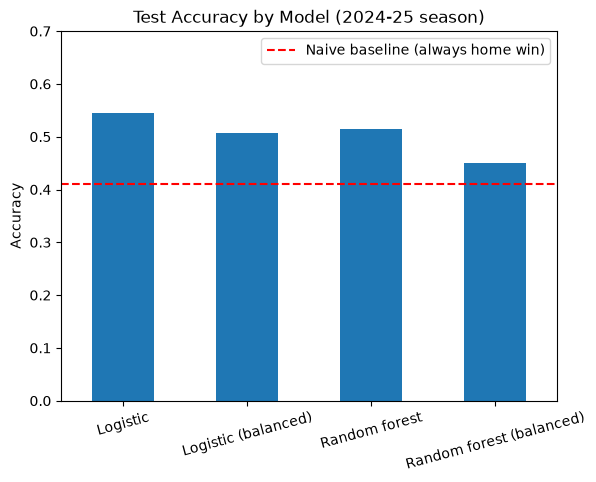

In [14]:
import os
os.makedirs('images', exist_ok=True)

accs = pd.Series({
    'Logistic': accuracy_score(y_test, y_pred_lr),
    'Logistic (balanced)': accuracy_score(y_test, y_pred_lr_balanced),
    'Random forest': accuracy_score(y_test, y_pred_rf),
    'Random forest (balanced)': accuracy_score(y_test, y_pred_rf_balanced),
})
accs.plot(kind='bar', rot=15)
plt.axhline((y_test == 2).mean(), color='red', linestyle='--', label='Naive baseline (always home win)')
plt.ylim(0, 0.7)
plt.ylabel('Accuracy')
plt.title('Test Accuracy by Model (2024-25 season)')
plt.legend()
plt.savefig('images/model_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Hyperparamter Tuning
GridSearchCV with time-ordered folds (TimeSeriesSplit) on the training data only. Tuning did not meaningfully change results, so the untuned models are kept as the final versions.


In [15]:
tscv = TimeSeriesSplit(n_splits=5)

# Logistic Regression
lr_pipe = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1000))])
lr_grid = GridSearchCV(lr_pipe, {'model__C': [0.001, 0.01, 0.1, 1, 10]}, cv=tscv, scoring='accuracy')
lr_grid.fit(X_train, y_train)

# Random Forest (no scaling needed)
rf_grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42),
    {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 5, 10, 20]},
    cv=tscv, scoring='accuracy'
)
rf_grid.fit(X_train, y_train)

# Tuned Logistic Regression
preds_lr = lr_grid.best_estimator_.predict(X_test)

print("TUNED LOGISTIC REGRESSION")
print("Best params:", lr_grid.best_params_)
print("Best CV accuracy:", round(lr_grid.best_score_, 3))
print("Test accuracy:", round(accuracy_score(y_test, preds_lr), 3))
print(confusion_matrix(y_test, preds_lr))
print(classification_report(y_test, preds_lr, target_names=le.classes_, zero_division=0))

# Tuned Random Forest
preds_rf = rf_grid.best_estimator_.predict(X_test)

print("TUNED RANDOM FOREST")
print("Best params:", rf_grid.best_params_)
print("Best CV accuracy:", round(rf_grid.best_score_, 3))
print("Test accuracy:", round(accuracy_score(y_test, preds_rf), 3))
print(confusion_matrix(y_test, preds_rf))
print(classification_report(y_test, preds_rf, target_names=le.classes_, zero_division=0))

TUNED LOGISTIC REGRESSION
Best params: {'model__C': 0.001}
Best CV accuracy: 0.534
Test accuracy: 0.536
[[ 69   0  62]
 [ 23   0  67]
 [ 22   0 132]]
              precision    recall  f1-score   support

           A       0.61      0.53      0.56       131
           D       0.00      0.00      0.00        90
           H       0.51      0.86      0.64       154

    accuracy                           0.54       375
   macro avg       0.37      0.46      0.40       375
weighted avg       0.42      0.54      0.46       375

TUNED RANDOM FOREST
Best params: {'max_depth': None, 'min_samples_leaf': 10}
Best CV accuracy: 0.534
Test accuracy: 0.512
[[ 66   0  65]
 [ 30   0  60]
 [ 28   0 126]]
              precision    recall  f1-score   support

           A       0.53      0.50      0.52       131
           D       0.00      0.00      0.00        90
           H       0.50      0.82      0.62       154

    accuracy                           0.51       375
   macro avg       0.34      

## 8. Regression: Expected Goals
Linear regression and random forest predict each team's xG in a match (separate home and away models), compared against a baseline that always predicts the training average.


In [16]:
y_train_xg_home = train['xg_home']
y_train_xg_away = train['xg_away']
y_test_xg_home = test['xg_home']
y_test_xg_away = test['xg_away']

# Naive baseline: always predict the training average xG for each side
base_home = np.full(len(test), y_train_xg_home.mean())
base_away = np.full(len(test), y_train_xg_away.mean())

print("Avg home xG (train):", round(y_train_xg_home.mean(), 2))
print("Avg away xG (train):", round(y_train_xg_away.mean(), 2))
print("Baseline RMSE - home:", round(np.sqrt(mean_squared_error(y_test_xg_home, base_home)), 3))
print("Baseline RMSE - away:", round(np.sqrt(mean_squared_error(y_test_xg_away, base_away)), 3))

Avg home xG (train): 1.65
Avg away xG (train): 1.34
Baseline RMSE - home: 0.945
Baseline RMSE - away: 0.945


In [17]:
# Bet365 odds normalized so the bookmaker's margin is removed
def add_odds_probs(df):
    total = 1/df['B365H'] + 1/df['B365D'] + 1/df['B365A']
    df['Odds_Prob_H'] = (1/df['B365H']) / total
    df['Odds_Prob_D'] = (1/df['B365D']) / total
    df['Odds_Prob_A'] = (1/df['B365A']) / total

add_odds_probs(train)
add_odds_probs(test)

# xG models use the 18 features plus the 3 odds probabilities 
xg_features = features + ['Odds_Prob_H', 'Odds_Prob_D', 'Odds_Prob_A']

# Separate scaler for the xG models, so the classifier's scaler stays untouched
xg_scaler = StandardScaler()
X_train_xg_scaled = xg_scaler.fit_transform(train[xg_features])
X_test_xg_scaled = xg_scaler.transform(test[xg_features])

print(X_train_xg_scaled.shape, X_test_xg_scaled.shape)

(1439, 21) (375, 21)


In [18]:
# 2 separate models, one for home and the other for away
lin_reg_home = LinearRegression()
lin_reg_home.fit(X_train_xg_scaled, y_train_xg_home)
pred_lin_reg_home_xg = lin_reg_home.predict(X_test_xg_scaled)

lin_reg_away = LinearRegression()
lin_reg_away.fit(X_train_xg_scaled, y_train_xg_away)
pred_lin_reg_away_xg = lin_reg_away.predict(X_test_xg_scaled)

print("LINEAR REGRESSION")
print("Home xG RMSE:", round(np.sqrt(mean_squared_error(y_test_xg_home, pred_lin_reg_home_xg)), 3),
      "| R²:", round(r2_score(y_test_xg_home, pred_lin_reg_home_xg), 3))
print("Away xG RMSE:", round(np.sqrt(mean_squared_error(y_test_xg_away, pred_lin_reg_away_xg)), 3),
      "| R²:", round(r2_score(y_test_xg_away, pred_lin_reg_away_xg), 3))

LINEAR REGRESSION
Home xG RMSE: 0.866 | R²: 0.16
Away xG RMSE: 0.821 | R²: 0.22


In [19]:
# Trees don't need scaling, so this uses the unscaled 21 features
rf_home = RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42)
rf_home.fit(train[xg_features], y_train_xg_home)
pred_rf_home_xg = rf_home.predict(test[xg_features])

rf_away = RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42)
rf_away.fit(train[xg_features], y_train_xg_away)
pred_rf_away_xg = rf_away.predict(test[xg_features])

print("RANDOM FOREST")
print("Home xG RMSE:", round(np.sqrt(mean_squared_error(y_test_xg_home, pred_rf_home_xg)), 3),
      "| R²:", round(r2_score(y_test_xg_home, pred_rf_home_xg), 3))
print("Away xG RMSE:", round(np.sqrt(mean_squared_error(y_test_xg_away, pred_rf_away_xg)), 3),
      "| R²:", round(r2_score(y_test_xg_away, pred_rf_away_xg), 3))

RANDOM FOREST
Home xG RMSE: 0.857 | R²: 0.176
Away xG RMSE: 0.829 | R²: 0.205


## 9. Combined Match Prediction
Combines the classifier and xG models to show outcome probabilities, predicted xG, and the model's pick for a match.


In [20]:
def predict_match(row):
    # Outcome probabilities: 18 features, classifier's scaler
    X_row = row[features].to_frame().T.astype(float)
    probs = log_reg.predict_proba(scaler.transform(X_row))[0]   # order: A, D, H

    # xG: 21 features (includes the odds probabilities), xG scaler
    X_row_xg = row[xg_features].to_frame().T.astype(float)
    X_row_xg_scaled = xg_scaler.transform(X_row_xg)
    xg_home = lin_reg_home.predict(X_row_xg_scaled)[0]
    xg_away = lin_reg_away.predict(X_row_xg_scaled)[0]

    pick = probs.argmax()   # 0 = away, 1 = draw, 2 = home
    if pick == 2:
        predicted = f"{row['HomeTeam']} win"
    elif pick == 0:
        predicted = f"{row['AwayTeam']} win"
    else:
        predicted = "Draw"

    actual_map = {'H': f"{row['HomeTeam']} win", 'A': f"{row['AwayTeam']} win", 'D': 'Draw'}
    actual = actual_map[row['FTR']]
    check = "correct" if predicted == actual else "incorrect"

    print(f"{row['HomeTeam']} vs {row['AwayTeam']}  ({row['Date'].date()})")
    print(f"  Home win: {probs[2]:.0%} | Draw: {probs[1]:.0%} | Away win: {probs[0]:.0%}")
    print(f"  Predicted xG: {xg_home:.2f} - {xg_away:.2f}")
    print(f"  Predicted: {predicted}  |  Actual: {actual}  ({check})")
    print(f"  Actual xG: {row['xg_home']:.2f} - {row['xg_away']:.2f}")
    print()

In [21]:
predict_match(test.iloc[0])
predict_match(test.iloc[1])
predict_match(test.iloc[2])

Manchester United vs Fulham  (2024-08-16)
  Home win: 51% | Draw: 25% | Away win: 25%
  Predicted xG: 1.98 - 1.16
  Predicted: Manchester United win  |  Actual: Manchester United win  (correct)
  Actual xG: 2.04 - 0.42

Nottingham Forest vs Bournemouth  (2024-08-17)
  Home win: 45% | Draw: 25% | Away win: 30%
  Predicted xG: 1.67 - 1.31
  Predicted: Nottingham Forest win  |  Actual: Draw  (incorrect)
  Actual xG: 1.24 - 1.91

Newcastle United vs Southampton  (2024-08-17)
  Home win: 88% | Draw: 8% | Away win: 4%
  Predicted xG: 2.72 - 0.95
  Predicted: Newcastle United win  |  Actual: Newcastle United win  (correct)
  Actual xG: 0.43 - 1.95



## 10. Save Trained Models
Saves the fitted scaler and models so they can be reused without retraining.

In [22]:
import joblib

os.makedirs('models', exist_ok=True)
joblib.dump(scaler, 'models/scaler.joblib')
joblib.dump(log_reg, 'models/log_reg.joblib')
joblib.dump(features, 'models/features.joblib')
joblib.dump(xg_scaler, 'models/xg_scaler.joblib')
joblib.dump(lin_reg_home, 'models/xg_home_model.joblib')
joblib.dump(lin_reg_away, 'models/xg_away_model.joblib')
joblib.dump(xg_features, 'models/xg_features.joblib')

['models/xg_features.joblib']